# LIBERO Similarity Debugger

A short, standalone rollout that visualizes timestamp-matched human and robot frames and computes the same DINOv3 cosine similarity used by the training reward wrapper.

## 1. Notebook Configuration and Debug Parameters

Edit these values to switch tasks, data, policy, camera, action mode, or rollout length.

In [1]:
import os
from pathlib import Path

SUITE = "libero_goal"
TASK_ID = 8
TASK_NAME = f"{SUITE}:{TASK_ID}"
DINO_MODEL_NAME = "dinov3_vitb16"
DINO_CHECKPOINT = os.environ.get(
    "DINO_CHECKPOINT",
    str(Path.home() / ".cache/torch/hub/checkpoints/EUPE-ViT-B.pt"),
)
POLICY_PATH = None  # Optional SB3 model zip; None uses scripted debug actions.
DEMO_VIDEO_PATH = Path("human_demo.mp4")
DEMO_EMBEDDINGS_PATH = Path("human_demo_embeddings.npy")
CAMERA_KEY = "wrist"  # The camera scored by DINOv3SimilarityReward.
NUM_DEBUG_STEPS = 20
FRAME_SELECTION = "nearest_timestamp"
DEVICE_NAME = "cuda" if __import__("torch").cuda.is_available() else "cpu"
SEED = 123
CONTROL_FREQ = 20
ACTION_MODE = "scripted"  # Set to "policy" when POLICY_PATH points to a PPO zip.
SCRIPTED_ACTION = (0.0, 0.0, -5.0, 0.0)  # x, y, z, gripper
ARTIFACT_DIR = Path("debug_artifacts")

## 2. Imports and Reproducibility

Seed Python, NumPy, and Torch so the scripted rollout is repeatable.

In [2]:
import csv
import random
from html import escape

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from IPython.display import HTML, display

from encode_human_video import load_video_embeddings
from policy import DINOv3VisionEncoder
from train import CONTROL_FREQ, LiberoEnv

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device(DEVICE_NAME)
PROJECT_ROOT = Path.cwd()
DEMO_VIDEO_PATH = PROJECT_ROOT / DEMO_VIDEO_PATH
DEMO_EMBEDDINGS_PATH = PROJECT_ROOT / DEMO_EMBEDDINGS_PATH
ARTIFACT_DIR = PROJECT_ROOT / ARTIFACT_DIR
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["image.cmap"] = "gray"

[robosuite WARNING] No private macro file found! (__init__.py:7)
[robosuite WARNING] It is recommended to use a private macro file (__init__.py:8)
[robosuite WARNING] To setup, run: python /home/liyouzhou/LearningFromHumanVideo/.venv/lib/python3.10/site-packages/robosuite/scripts/setup_macros.py (__init__.py:9)


## 3. LIBERO Environment Factory

This factory returns a fresh, reset task environment with the configured camera and proprioceptive observations.

In [3]:
def make_debug_env():
    env = LiberoEnv(suite=SUITE, task_id=TASK_ID, seed=SEED, max_steps=NUM_DEBUG_STEPS)
    observation, _ = env.reset(seed=SEED)
    required_keys = {CAMERA_KEY, "wrist", "proprio"}
    missing = required_keys.difference(observation)
    if missing:
        env.close()
        raise KeyError(f"LIBERO observation is missing keys: {sorted(missing)}")
    return env, observation

## 4. Load and Preprocess Human Demo Frames

Use the precomputed timestamps and DINOv3 embeddings for reward-aligned frame selection. Original RGB frames are loaded from the records when available, otherwise decoded from the source MP4.

In [4]:
records = load_video_embeddings(DEMO_EMBEDDINGS_PATH)
human_timestamps = np.asarray(records["timestamp"], dtype=np.float64)
human_frame_numbers = np.asarray(records["frame_number"], dtype=np.int64)
human_embedding_tensor = F.normalize(
    torch.as_tensor(records["embedding"], dtype=torch.float32, device=DEVICE), dim=1
)
DEMO_EPISODE_ID = 0  # This embedding file represents one demo episode.

if ACTION_MODE == "policy":
    if not POLICY_PATH:
        raise ValueError("Set POLICY_PATH before using ACTION_MODE='policy'.")
    from stable_baselines3 import PPO

    debug_policy = PPO.load(POLICY_PATH, device=DEVICE)
    vision_encoder = debug_policy.policy.features_extractor.vision_encoder
else:
    vision_encoder = DINOv3VisionEncoder(
        model_name=DINO_MODEL_NAME,
        checkpoint_path=DINO_CHECKPOINT,
        freeze_backbone=True,
    ).to(DEVICE)
    debug_policy = None
vision_encoder.eval()

has_stored_frames = "original_frame" in records.dtype.names
human_capture = None if has_stored_frames else cv2.VideoCapture(str(DEMO_VIDEO_PATH))
if human_capture is not None and not human_capture.isOpened():
    raise ValueError(f"Could not open demo video: {DEMO_VIDEO_PATH}")


def center_crop_resize_rgb(frame, size=224):
    height, width = frame.shape[:2]
    scale = size / min(height, width)
    resized = cv2.resize(frame, (round(width * scale), round(height * scale)))
    top = (resized.shape[0] - size) // 2
    left = (resized.shape[1] - size) // 2
    return np.ascontiguousarray(resized[top : top + size, left : left + size])


def get_human_frame(record_index):
    if has_stored_frames:
        frame = records["original_frame"][record_index]
    else:
        human_capture.set(cv2.CAP_PROP_POS_FRAMES, int(human_frame_numbers[record_index]))
        ok, frame_bgr = human_capture.read()
        if not ok:
            raise ValueError(f"Could not decode demo frame {human_frame_numbers[record_index]}.")
        frame = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
    return center_crop_resize_rgb(frame)

print(
    f"Loaded {len(records)} demo frames; stored RGB frames={has_stored_frames}; "
    f"DINO device={DEVICE}; demo episode={DEMO_EPISODE_ID}."
)

Using cache found in /home/liyouzhou/.cache/torch/hub/facebookresearch_dinov3_main
/home/liyouzhou/LearningFromHumanVideo/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loaded 192 demo frames; stored RGB frames=True; DINO device=cuda; demo episode=0.


## 5. Run a Short Debug Rollout

This notebook-only loop uses a scripted 4D action by default, or a loaded PPO policy when configured. It does not invoke the training entry point.

In [5]:
env, observation = make_debug_env()
debug_rows = []

try:
    for step_index in range(NUM_DEBUG_STEPS):
        elapsed_seconds = (step_index + 1) / CONTROL_FREQ
        if FRAME_SELECTION != "nearest_timestamp":
            raise ValueError(f"Unsupported frame selection strategy: {FRAME_SELECTION}")
        human_index = int(np.argmin(np.abs(human_timestamps - elapsed_seconds)))
        human_frame = get_human_frame(human_index)

        if ACTION_MODE == "policy":
            action, _ = debug_policy.predict(observation, deterministic=True)
        else:
            action = np.asarray(SCRIPTED_ACTION, dtype=np.float32)
        action = np.asarray(action, dtype=np.float32)
        if action.shape != (4,):
            raise ValueError(f"Expected policy/scripted action shape (4,), got {action.shape}.")

        next_observation, env_reward, terminated, truncated, info = env.step(action)
        debug_rows.append(
            {
                "step": step_index + 1,
                "elapsed_seconds": elapsed_seconds,
                "human_index": human_index,
                "human_frame_number": int(human_frame_numbers[human_index]),
                "human_timestamp": float(human_timestamps[human_index]),
                "human_frame": human_frame,
                "observation": next_observation,
                "env_reward": float(env_reward),
                "terminated": bool(terminated),
                "truncated": bool(truncated),
                "success": bool(info.get("is_success", False)),
            }
        )
        observation = next_observation
        if terminated or truncated:
            break
finally:
    env.close()
    if human_capture is not None:
        human_capture.release()

print(f"Recorded {len(debug_rows)} environment steps.")

[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Local assets not found. Downloading from HuggingFace Hub...
Assets already downloaded at /home/liyouzhou/.cache/libero/assets
Recorded 20 environment steps.


In [6]:
env, observation = make_debug_env()  # Assuming a function reset_env() exists to reset the environment and return the initial observation.

[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


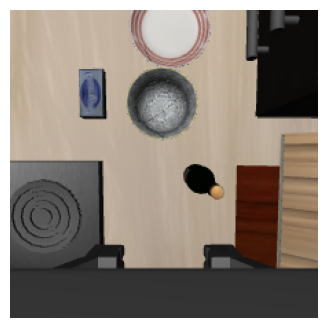

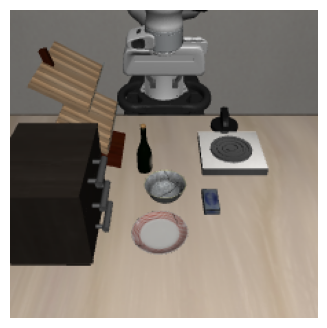

In [7]:
action = [0,0,0,-1]
next_observation, env_reward, terminated, truncated, info = env.step(action)

import numpy as np

import matplotlib.pyplot as plt


plt.imshow(next_observation["wrist"])

plt.axis("off")

plt.show()

plt.figure()
plt.imshow(next_observation["agentview"])
plt.axis("off")
plt.show()

In [8]:
next_observation["raw"].keys()

KeyError: 'raw'

In [ ]:
import libero

## 6. Capture Robot Camera Frames

Keep camera images synchronized with rollout step numbers and selected human frame indices.

In [ ]:
step_indices = np.asarray([row["step"] for row in debug_rows], dtype=np.int64)
robot_frames = [np.ascontiguousarray(row["observation"][CAMERA_KEY]) for row in debug_rows]
wrist_frames = [np.ascontiguousarray(row["observation"]["wrist"]) for row in debug_rows]
selected_human_frames = [row["human_frame"] for row in debug_rows]
selected_human_indices = np.asarray([row["human_index"] for row in debug_rows], dtype=np.int64)
print(f"Captured {len(robot_frames)} {CAMERA_KEY} and wrist frames.")

Captured 20 wrist and wrist frames.


## 7. Compute Frame Similarity Scores

This uses the same global DINOv3 embeddings, L2 normalization, and cosine similarity as `DINOv3SimilarityReward`; the environment success bonus is reported separately.

In [ ]:
robot_batch = torch.as_tensor(np.stack(robot_frames), device=DEVICE)
if robot_batch.shape[-1] == 3:
    robot_batch = robot_batch.permute(0, 3, 1, 2)
elif robot_batch.shape[1] != 3:
    raise ValueError(f"Unexpected robot image shape: {tuple(robot_batch.shape)}")

with torch.inference_mode():
    vision_encoder.backbone.eval()
    robot_embeddings = F.normalize(vision_encoder.global_embedding(robot_batch), dim=1)
    matched_human_embeddings = human_embedding_tensor[
        torch.as_tensor(selected_human_indices, device=DEVICE)
    ]
    similarity_scores = F.cosine_similarity(
        robot_embeddings, matched_human_embeddings, dim=1
    ).cpu().numpy()

for row, similarity in zip(debug_rows, similarity_scores):
    row["similarity"] = float(similarity)
    row["total_reward"] = float(similarity) + float(row["success"])

debug_results = [
    {
        "step": row["step"],
        "elapsed_seconds": row["elapsed_seconds"],
        "human_episode": DEMO_EPISODE_ID,
        "human_frame_index": row["human_index"],
        "human_frame_number": row["human_frame_number"],
        "human_timestamp": row["human_timestamp"],
        "similarity": row["similarity"],
        "success": row["success"],
        "total_reward": row["total_reward"],
        "terminated": row["terminated"],
        "truncated": row["truncated"],
    }
    for row in debug_rows
]
with (ARTIFACT_DIR / "similarity_debug.csv").open("w", newline="") as output_file:
    writer = csv.DictWriter(output_file, fieldnames=list(debug_results[0]))
    writer.writeheader()
    writer.writerows(debug_results)


def display_table(rows):
    if not rows:
        print("No rows to display.")
        return
    columns = list(rows[0])
    header = "".join(f"<th>{escape(column)}</th>" for column in columns)
    body = "".join(
        "<tr>" + "".join(f"<td>{escape(str(row[column]))}</td>" for column in columns) + "</tr>"
        for row in rows
    )
    display(HTML(f"<table><thead><tr>{header}</tr></thead><tbody>{body}</tbody></table>"))


display_table(debug_results)

step,elapsed_seconds,human_episode,human_frame_index,human_frame_number,human_timestamp,similarity,success,total_reward,terminated,truncated
1,0.05,0,1,1,0.033337435897435895,0.3905870020389557,False,0.3905870020389557,False,False
2,0.1,0,3,3,0.10001230769230769,0.39333871006965637,False,0.39333871006965637,False,False
3,0.15,0,4,4,0.13334974358974358,0.36803770065307617,False,0.36803770065307617,False,False
4,0.2,0,6,6,0.20002461538461538,0.38909345865249634,False,0.38909345865249634,False,False
5,0.25,0,7,7,0.23336205128205129,0.4062877297401428,False,0.4062877297401428,False,False
6,0.3,0,9,9,0.3000369230769231,0.4137948155403137,False,0.4137948155403137,False,False
7,0.35,0,10,10,0.33337435897435896,0.41701409220695496,False,0.41701409220695496,False,False
8,0.4,0,12,12,0.40004923076923077,0.41180098056793213,False,0.41180098056793213,False,False
9,0.45,0,13,13,0.43338666666666664,0.4505147933959961,False,0.4505147933959961,False,False
10,0.5,0,15,15,0.5000615384615384,0.38352495431900024,False,0.38352495431900024,False,False


## 8. Visualize Matched Demo and Robot Images

Each row shows the selected human frame, the scored robot camera frame, and the robot wrist view with step/time and similarity annotations.

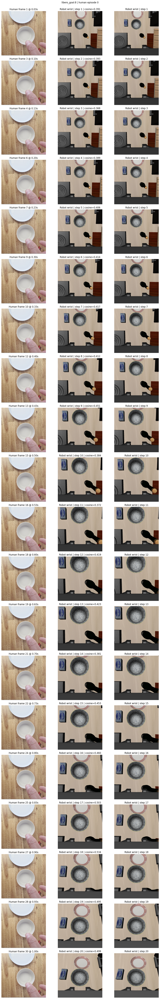

In [ ]:
fig, axes = plt.subplots(len(debug_rows), 3, figsize=(13, 3.6 * len(debug_rows)), squeeze=False)
for row_index, row in enumerate(debug_rows):
    axes[row_index, 0].imshow(row["human_frame"])
    axes[row_index, 0].set_title(
        f"Human frame {row['human_frame_number']} @ {row['human_timestamp']:.2f}s"
    )
    axes[row_index, 1].imshow(robot_frames[row_index])
    axes[row_index, 1].set_title(
        f"Robot {CAMERA_KEY} | step {row['step']} | cosine={row['similarity']:.3f}"
    )
    axes[row_index, 2].imshow(wrist_frames[row_index])
    axes[row_index, 2].set_title(f"Robot wrist | step {row['step']}")
    for axis in axes[row_index]:
        axis.axis("off")
fig.suptitle(f"{TASK_NAME} | human episode {DEMO_EPISODE_ID}", y=1.0)
fig.tight_layout()
plt.show()

## 9. Plot Similarity Across Steps

Mark the best matching step and any successful step on the score trend.

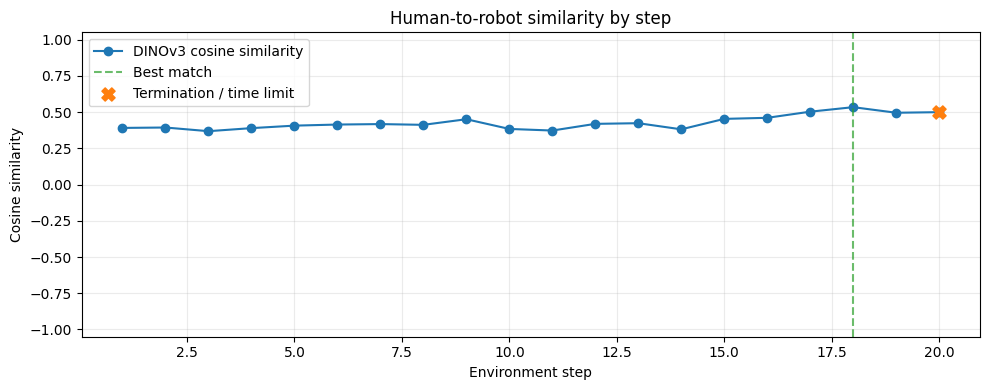

Mean similarity: 0.4281
Best match: step 18, score 0.5337
Episode success: False


In [ ]:
fig, axis = plt.subplots(figsize=(10, 4))
axis.plot(step_indices, similarity_scores, marker="o", label="DINOv3 cosine similarity")
best_position = int(np.argmax(similarity_scores))
axis.axvline(step_indices[best_position], linestyle="--", color="tab:green", alpha=0.7, label="Best match")
success_positions = [i for i, row in enumerate(debug_rows) if row["success"]]
if success_positions:
    axis.scatter(
        step_indices[success_positions],
        similarity_scores[success_positions],
        marker="*",
        s=150,
        color="tab:red",
        label="Success",
        zorder=3,
    )
end_positions = [
    i for i, row in enumerate(debug_rows) if row["terminated"] or row["truncated"]
]
if end_positions:
    axis.scatter(
        step_indices[end_positions],
        similarity_scores[end_positions],
        marker="X",
        s=90,
        color="tab:orange",
        label="Termination / time limit",
        zorder=4,
    )
axis.set(title="Human-to-robot similarity by step", xlabel="Environment step", ylabel="Cosine similarity", ylim=(-1.05, 1.05))
axis.grid(True, alpha=0.25)
axis.legend()
fig.tight_layout()
plt.show()

print(f"Mean similarity: {np.mean(similarity_scores):.4f}")
print(f"Best match: step {int(step_indices[best_position])}, score {similarity_scores[best_position]:.4f}")
print(f"Episode success: {any(row['success'] for row in debug_rows)}")

## 10. Optional External Debug Script

Set a script path to run a separate helper process. It receives the requested step count and CSV destination through environment variables; if it writes that CSV, the notebook reloads and displays it.

In [ ]:
import subprocess
import sys

EXTERNAL_DEBUG_SCRIPT = None  # Example: PROJECT_ROOT / "debug_rollout.py"
EXTERNAL_RESULTS_CSV = ARTIFACT_DIR / "external_similarity_debug.csv"

if EXTERNAL_DEBUG_SCRIPT is None:
    print("External script skipped; the notebook rollout above ran directly.")
else:
    completed = subprocess.run(
        [sys.executable, str(EXTERNAL_DEBUG_SCRIPT)],
        check=True,
        capture_output=True,
        text=True,
        env={
            **os.environ,
            "DEBUG_NUM_STEPS": str(NUM_DEBUG_STEPS),
            "DEBUG_OUTPUT_CSV": str(EXTERNAL_RESULTS_CSV),
        },
    )
    print(completed.stdout)
    if completed.stderr:
        print(completed.stderr)
    if EXTERNAL_RESULTS_CSV.is_file():
        with EXTERNAL_RESULTS_CSV.open(newline="") as input_file:
            external_results = list(csv.DictReader(input_file))
        display_table(external_results)
        if external_results and {"step", "similarity"}.issubset(external_results[0]):
            external_steps = [float(row["step"]) for row in external_results]
            external_scores = [float(row["similarity"]) for row in external_results]
            plt.plot(external_steps, external_scores, marker="o")
            plt.title("External rollout similarity")
            plt.xlabel("Environment step")
            plt.ylabel("Cosine similarity")
            plt.grid(True, alpha=0.25)
            plt.show()

External script skipped; the notebook rollout above ran directly.


## 11. Score a Training Eval Video

Split a saved eval video into its agent-view (left) and wrist (right) halves, pair every frame with the human frame at the same timestamp, and compute the DINOv3 cosine similarity of the scored half.

In [ ]:
EVAL_VIDEO_PATH = PROJECT_ROOT / "runs/eval_videos/step_000350000/episode_02_h264.mp4"
EVAL_VIDEO_PATH = PROJECT_ROOT / "runs/eval_videos/step_000300000/episode_02.mp4"
SCORE_VIEW = "wrist"  # Matches the camera DINOv3SimilarityReward scores; "agentview" scores the left half.

eval_capture = cv2.VideoCapture(str(EVAL_VIDEO_PATH))
if not eval_capture.isOpened():
    raise ValueError(f"Could not open eval video: {EVAL_VIDEO_PATH}")
eval_fps = eval_capture.get(cv2.CAP_PROP_FPS)
if abs(eval_fps - CONTROL_FREQ) > 1e-3:
    raise ValueError(f"Eval video is {eval_fps} FPS but the environment runs at {CONTROL_FREQ} Hz.")

eval_frames = []
while True:
    ok, frame_bgr = eval_capture.read()
    if not ok:
        break
    eval_frames.append(cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB))
eval_capture.release()

half_width = eval_frames[0].shape[1] // 2
agentview_eval = [frame[:, :half_width] for frame in eval_frames]
wrist_eval = [frame[:, half_width:] for frame in eval_frames]
scored_eval = wrist_eval if SCORE_VIEW == "wrist" else agentview_eval

# Frame 0 is the reset observation; frame k is the observation after k steps.
eval_timestamps = np.arange(len(eval_frames)) / CONTROL_FREQ
eval_human_indices = np.asarray(
    [int(np.argmin(np.abs(human_timestamps - t))) for t in eval_timestamps], dtype=np.int64
)

needed_numbers = {int(human_frame_numbers[i]) for i in eval_human_indices}
human_by_number = {}
human_reader = cv2.VideoCapture(str(DEMO_VIDEO_PATH))
frame_number = 0
while frame_number <= max(needed_numbers):
    ok, frame_bgr = human_reader.read()
    if not ok:
        raise ValueError(f"Demo video ended before frame {max(needed_numbers)}.")
    if frame_number in needed_numbers:
        human_by_number[frame_number] = center_crop_resize_rgb(cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB))
    frame_number += 1
human_reader.release()
eval_human_frames = [human_by_number[int(human_frame_numbers[i])] for i in eval_human_indices]

scores = []
with torch.inference_mode():
    vision_encoder.backbone.eval()
    for start in range(0, len(scored_eval), 32):
        batch = torch.as_tensor(np.stack(scored_eval[start : start + 32]), device=DEVICE).permute(0, 3, 1, 2)
        robot_embeddings = F.normalize(vision_encoder.global_embedding(batch), dim=1)
        targets = human_embedding_tensor[torch.as_tensor(eval_human_indices[start : start + 32], device=DEVICE)]
        scores.append(F.cosine_similarity(robot_embeddings, targets, dim=1).cpu().numpy())
eval_similarity = np.concatenate(scores)

print(
    f"{len(eval_frames)} frames ({SCORE_VIEW} scored); mean similarity {eval_similarity.mean():.4f}, "
    f"min {eval_similarity.min():.4f}, max {eval_similarity.max():.4f}"
)


101 frames (wrist scored); mean similarity 0.5273, min 0.3373, max 0.6182


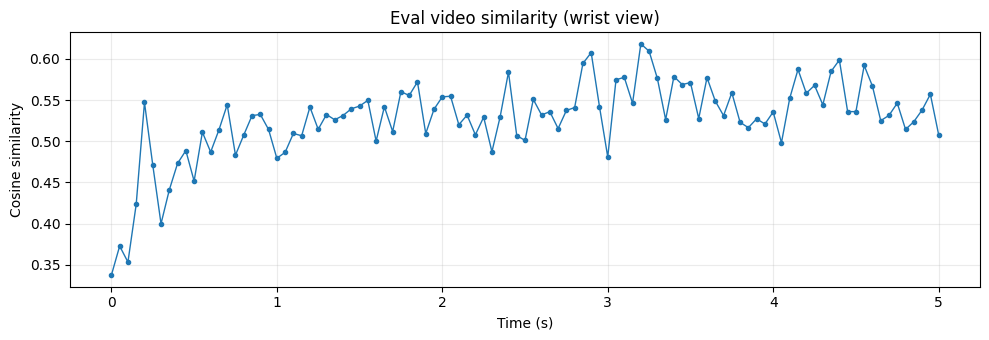

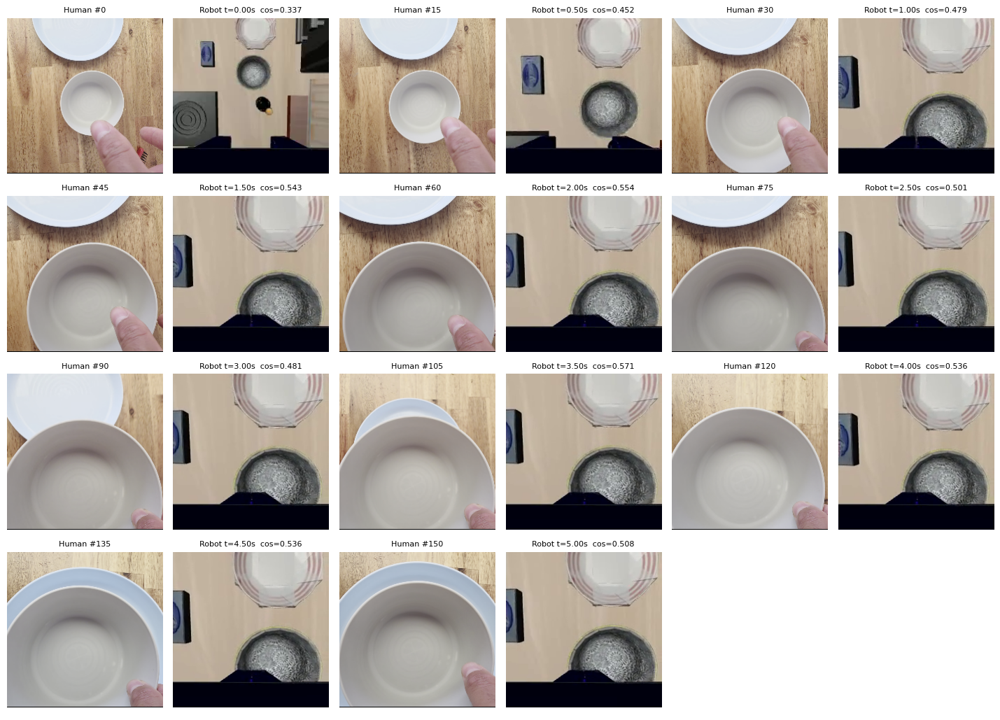

In [ ]:
PLOT_STRIDE = 10  # Set to 1 to plot every frame pair.

fig, axis = plt.subplots(figsize=(10, 3.5))
axis.plot(eval_timestamps, eval_similarity, marker=".", linewidth=1)
axis.set(title=f"Eval video similarity ({SCORE_VIEW} view)", xlabel="Time (s)", ylabel="Cosine similarity")
axis.grid(True, alpha=0.25)
fig.tight_layout()
plt.show()

shown = list(range(0, len(eval_frames), PLOT_STRIDE))
columns = 3
rows = (len(shown) + columns - 1) // columns
fig, axes = plt.subplots(rows, columns * 2, figsize=(4 * columns * 2 * 0.6, 2.6 * rows), squeeze=False)
for axis in axes.ravel():
    axis.axis("off")
for slot, frame_index in enumerate(shown):
    row, column = divmod(slot, columns)
    axes[row, column * 2].imshow(eval_human_frames[frame_index])
    axes[row, column * 2].set_title(f"Human #{int(human_frame_numbers[eval_human_indices[frame_index]])}", fontsize=8)
    axes[row, column * 2 + 1].imshow(scored_eval[frame_index])
    axes[row, column * 2 + 1].set_title(
        f"Robot t={eval_timestamps[frame_index]:.2f}s  cos={eval_similarity[frame_index]:.3f}", fontsize=8
    )
fig.tight_layout()
plt.show()


In [ ]:
import subprocess

from IPython.display import Video

OVERLAY_SCALE = 2
overlay_raw_path = ARTIFACT_DIR / f"{EVAL_VIDEO_PATH.stem}_similarity_raw.mp4"
overlay_path = ARTIFACT_DIR / f"{EVAL_VIDEO_PATH.stem}_similarity.mp4"


def draw_label(image, text, origin, color=(255, 255, 255)):
    cv2.putText(image, text, origin, cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 4, cv2.LINE_AA)
    cv2.putText(image, text, origin, cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 1, cv2.LINE_AA)


def human_frame_width():
    return eval_human_frames[0].shape[1] * OVERLAY_SCALE


def compose_frame(index):
    robot = eval_frames[index].copy()
    scored_x = half_width if SCORE_VIEW == "wrist" else 0
    cv2.rectangle(robot, (scored_x, 0), (scored_x + half_width - 1, robot.shape[0] - 1), (255, 255, 0), 2)
    canvas = np.concatenate((eval_human_frames[index], robot), axis=1)
    canvas = cv2.resize(canvas, None, fx=OVERLAY_SCALE, fy=OVERLAY_SCALE, interpolation=cv2.INTER_LINEAR)

    score = float(eval_similarity[index])
    bar_width = int((canvas.shape[1] - 20) * (max(score, 0.0)))
    cv2.rectangle(canvas, (10, canvas.shape[0] - 22), (canvas.shape[1] - 10, canvas.shape[0] - 10), (40, 40, 40), -1)
    cv2.rectangle(canvas, (10, canvas.shape[0] - 22), (10 + bar_width, canvas.shape[0] - 10), (80, 220, 80), -1)

    human_number = int(human_frame_numbers[eval_human_indices[index]])
    draw_label(canvas, f"Human frame {human_number}", (10, 24))
    draw_label(canvas, f"Robot t={eval_timestamps[index]:.2f}s", (human_frame_width() + 10, 24))
    draw_label(canvas, f"cosine similarity {score:.3f}", (10, canvas.shape[0] - 32), (120, 255, 120))
    return canvas


first = compose_frame(0)
writer = cv2.VideoWriter(
    str(overlay_raw_path),
    cv2.VideoWriter.fourcc(*"mp4v"),
    CONTROL_FREQ,
    (first.shape[1], first.shape[0]),
)
try:
    for frame_index in range(len(eval_frames)):
        writer.write(cv2.cvtColor(compose_frame(frame_index), cv2.COLOR_RGB2BGR))
finally:
    writer.release()

subprocess.run(
    [
        "ffmpeg", "-hide_banner", "-loglevel", "error", "-y", "-i", str(overlay_raw_path),
        "-c:v", "libx264", "-pix_fmt", "yuv420p", "-movflags", "+faststart", "-an", str(overlay_path),
    ],
    check=True,
)
overlay_raw_path.unlink()
print(f"Wrote {overlay_path}")
Video(str(overlay_path), embed=True, mimetype="video/mp4")


Wrote /home/liyouzhou/LearningFromHumanVideo/debug_artifacts/episode_02_similarity.mp4
